In [ ]:
!pip install -q transformers datasets torch huggingface_hub sentencepiece scipy numpy matplotlib

In [ ]:
import os
import random
from pathlib import Path

import numpy as np
import torch
# import matplotlib.subplots as subplots
import matplotlib.pyplot as plt
from scipy.stats import pearsonr
from datasets import load_dataset
from huggingface_hub import login
from transformers import AutoModelForCausalLM, AutoTokenizer

# ====== User-configurable ======
MODEL_ID = "meta-llama/Llama-3.2-1B-Instruct"
NUM_SAMPLES = 100          # Number of prompts to evaluate
MAX_INPUT_TOKENS = 128     # Reduce if you hit memory issues
OUT_DIR = Path("qkv_outputs")
STORE_DTYPE = torch.float16

# For the new experiments, we define multiple layers to extract
LAYERS_TO_EXTRACT = [5, 6, 7, 8]
# ===============================

# Setup device and directories
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print("Device:", DEVICE)
if DEVICE == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))

OUT_DIR.mkdir(parents=True, exist_ok=True)
torch.set_grad_enabled(False)

# Seed for reproducibility
random.seed(42)
np.random.seed(42)
torch.manual_seed(42)

# ====== Hugging Face Login ======
HF_TOKEN = os.getenv("HF_TOKEN")
if not HF_TOKEN:
    try:
        from google.colab import userdata
        HF_TOKEN = userdata.get("HF_TOKEN")
        if HF_TOKEN:
            print("HF token loaded from Colab Secrets.")
    except Exception:
        pass

if not HF_TOKEN:
    from getpass import getpass
    HF_TOKEN = getpass("Enter your Hugging Face token (hf_...): ").strip()

if HF_TOKEN:
    login(token=HF_TOKEN, add_to_git_credential=False)
    print("HF login: OK")
else:
    raise ValueError("HF token is required for this model. Set Colab secret HF_TOKEN or enter it when prompted.")

Device: cuda
GPU: Tesla T4
Enter your Hugging Face token (hf_...): ··········
HF login: OK


In [ ]:
print(f"Loading Tokenizer for {MODEL_ID}...")
tokenizer = AutoTokenizer.from_pretrained(MODEL_ID)
if tokenizer.pad_token is None:
    tokenizer.pad_token = tokenizer.eos_token

print(f"Loading Model {MODEL_ID}...")
model = AutoModelForCausalLM.from_pretrained(
    MODEL_ID,
    torch_dtype=STORE_DTYPE,
    device_map="auto"
)

# Extract config details for later reshaping
NUM_HEADS = model.config.num_attention_heads
HIDDEN_SIZE = model.config.hidden_size
HEAD_DIM = HIDDEN_SIZE // NUM_HEADS
print(f"Model loaded! Hidden Size: {HIDDEN_SIZE}, Q-Heads: {NUM_HEADS}, Head Dim: {HEAD_DIM}")

Loading Tokenizer for meta-llama/Llama-3.2-1B-Instruct...


/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


config.json:   0%|          | 0.00/877 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/54.5k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/9.09M [00:00<?, ?B/s]

...

Loading Model meta-llama/Llama-3.2-1B-Instruct...


model.safetensors:   0%|          | 0.00/2.47G [00:00<?, ?B/s]

Loading weights:   0%|          | 0/146 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/189 [00:00<?, ?B/s]

Model loaded! Hidden Size: 2048, Q-Heads: 32, Head Dim: 64


In [ ]:
print(f"Loading {NUM_SAMPLES} samples from ShareGPT...")

# Load ShareGPT instruct dataset
sharegpt = load_dataset("CaterinaLac/sharegpt-deduplicated", split=f"train[:{NUM_SAMPLES}]")

def build_sharegpt_prompt(row):
    """
    Builds a prompt in the same format as ShareGPT:
    Instruction: <instruction>
    Input: <input>      (optional)
    Response: <response>
    """
    instruction = row.get("input", "").strip()   # treat "input" as instruction
    inp = ""
    response = row.get("output", "").strip()

    if inp:
        return f"Instruction:\n{instruction}\n\nInput:\n{inp}\n\nResponse:\n{response}"
    else:
        return f"Instruction:\n{instruction}\n\nResponse:\n{response}"

prompts = [build_sharegpt_prompt(r) for r in sharegpt]

print("Loaded prompts:", len(prompts))
print("Sample prompt snippet:\n", prompts[0][:200], "...")

Loading 100 samples from ShareGPT...


README.md: 0.00B [00:00, ?B/s]

train.jsonl:   0%|          | 0.00/71.2M [00:00<?, ?B/s]

validation.jsonl: 0.00B [00:00, ?B/s]

Generating train split:   0%|          | 0/5040 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/100 [00:00<?, ? examples/s]

Loaded prompts: 100
Sample prompt snippet:
 Instruction:
Human: I want to build a DIY pool heater controller for my Mastertemp 250 pool heater. I have an ARDUINO UNO WiFi REV2 to use for this project. Can you help me to know what else I'll need ...


In [ ]:
extracted_q = {l: [] for l in LAYERS_TO_EXTRACT}

def get_q_hook(layer_idx):
    """Creates a hook to capture the output of the q_proj layer."""
    def hook(module, input, output):
        # output shape: [batch_size, seq_len, hidden_size]
        extracted_q[layer_idx].append(output.detach().cpu())
    return hook

hook_handles = []
print(f"Registering hooks for layers: {LAYERS_TO_EXTRACT}...")
for l_idx in LAYERS_TO_EXTRACT:
    handle = model.model.layers[l_idx].self_attn.q_proj.register_forward_hook(get_q_hook(l_idx))
    hook_handles.append(handle)

print(f"Running forward passes to extract Q states for {NUM_SAMPLES} samples...")
model.eval()

for i, prompt in enumerate(prompts):
    inputs = tokenizer(prompt, return_tensors="pt", truncation=True, max_length=MAX_INPUT_TOKENS).to(DEVICE)
    _ = model(**inputs)

    if (i + 1) % 20 == 0:
        print(f"Processed {i + 1}/{NUM_SAMPLES} prompts...")

# Remove hooks
for handle in hook_handles:
    handle.remove()

for l_idx in LAYERS_TO_EXTRACT:
    print(f"Layer {l_idx} extracted: {len(extracted_q[l_idx])} sequences.")

Registering hooks for layers: [5, 6, 7, 8]...
Running forward passes to extract Q states for 100 samples...
Processed 20/100 prompts...
Processed 40/100 prompts...
Processed 60/100 prompts...
Processed 80/100 prompts...
Processed 100/100 prompts...
Layer 5 extracted: 100 sequences.
Layer 6 extracted: 100 sequences.
Layer 7 extracted: 100 sequences.
Layer 8 extracted: 100 sequences.


In [ ]:
# import torch

# extracted_q = {l: [] for l in LAYERS_TO_EXTRACT}

# def get_q_hook(layer_idx):
#     """Creates a hook to capture the output of the q_proj layer."""
#     def hook(module, input, output):
#         # output shape: [batch_size, seq_len, hidden_size]
#         extracted_q[layer_idx].append(output.detach().cpu())
#     return hook

# hook_handles = []
# print(f"Registering hooks for layers: {LAYERS_TO_EXTRACT}...")
# for l_idx in LAYERS_TO_EXTRACT:
#     handle = model.model.layers[l_idx].self_attn.q_proj.register_forward_hook(get_q_hook(l_idx))
#     hook_handles.append(handle)

# print(f"Running forward passes to extract Q states for {NUM_SAMPLES} samples...")
# model.eval()

# # Ensure pad token is set for batching
# if tokenizer.pad_token is None:
#     tokenizer.pad_token = tokenizer.eos_token

# BATCH_SIZE = 16  # Process 8 sequences at a time (increase to 16 if your GPU has enough VRAM)

# # The torch.no_grad() context manager provides a massive speedup!
# with torch.no_grad():
#     for i in range(0, len(prompts), BATCH_SIZE):
#         batch_prompts = prompts[i : i + BATCH_SIZE]

#         # Tokenize as a batch, adding padding so sequences in the batch have the same length
#         inputs = tokenizer(
#             batch_prompts,
#             return_tensors="pt",
#             padding=True,
#             truncation=True,
#             max_length=MAX_INPUT_TOKENS
#         ).to(DEVICE)

#         _ = model(**inputs)

#         processed_count = min(i + BATCH_SIZE, len(prompts))
#         if processed_count % 20 == 0 or processed_count == len(prompts):
#             print(f"Processed {processed_count}/{NUM_SAMPLES} prompts...")

# # Remove hooks so they don't leak memory in future cells
# for handle in hook_handles:
#     handle.remove()

# for l_idx in LAYERS_TO_EXTRACT:
#     print(f"Layer {l_idx} extracted batches: {len(extracted_q[l_idx])}")

Registering hooks for layers: [5, 6, 7, 8]...
Running forward passes to extract Q states for 100 samples...


KeyboardInterrupt: 

In [ ]:
def get_flattened_head_vectors(layer_idx, head_idx):
    """
    Takes the extracted Q tensor list for a layer, reshapes it to isolate the specific head,
    and flattens it into a 1D numpy array.
    """
    head_vectors = []
    for seq_tensor in extracted_q[layer_idx]:
        # seq_tensor shape: [1, seq_len, hidden_size]
        batch, seq_len, _ = seq_tensor.shape
        reshaped = seq_tensor.view(batch, seq_len, NUM_HEADS, HEAD_DIM)

        # Isolate the specific head and flatten
        isolated_head = reshaped[:, :, head_idx, :].flatten().numpy()
        # Convert to float32 for scipy pearson correlation to avoid float16 overflow issues
        head_vectors.append(isolated_head.astype(np.float32))

    return np.concatenate(head_vectors)

def plot_head_correlations(layer_A, layer_B, num_pairs=10):
    """
    Plots correlation between randomly chosen heads of layer_A and layer_B.
    Ensures 1-2 plots compare the exact same head index.
    """
    pairs = []

    # 1. Force 1-2 identical head pairs (e.g., L5H3 vs L6H3)
    identical_heads_count = random.choice([1, 2])
    for _ in range(identical_heads_count):
        h = random.randint(0, NUM_HEADS - 1)
        pairs.append((h, h))

    # 2. Fill the rest with random pairs
    while len(pairs) < num_pairs:
        hA = random.randint(0, NUM_HEADS - 1)
        hB = random.randint(0, NUM_HEADS - 1)
        if (hA, hB) not in pairs:
            pairs.append((hA, hB))

    # Setup subplots
    cols = 5
    rows = (num_pairs + cols - 1) // cols
    fig, axes = plt.subplots(rows, cols, figsize=(20, 4 * rows))
    axes = axes.flatten()

    for i, (hA, hB) in enumerate(pairs):
        vec_A = get_flattened_head_vectors(layer_A, hA)
        vec_B = get_flattened_head_vectors(layer_B, hB)

        min_len = min(len(vec_A), len(vec_B))
        vec_A = vec_A[:min_len]
        vec_B = vec_B[:min_len]

        # Calculate Correlation
        corr, _ = pearsonr(vec_A, vec_B)

        # Sample points to not freeze the browser when rendering thousands of scatter dots
        sample_indices = np.random.choice(min_len, size=min(3000, min_len), replace=False)

        ax = axes[i]
        ax.scatter(vec_A[sample_indices], vec_B[sample_indices], alpha=0.3, s=2, color='darkcyan')
        ax.set_title(f"L{layer_A}H{hA} vs L{layer_B}H{hB}\nCorr: {corr:.3f}")
        ax.set_xlabel(f"L{layer_A} Head {hA}")
        ax.set_ylabel(f"L{layer_B} Head {hB}")

    # Hide unused subplots
    for j in range(i + 1, len(axes)):
        axes[j].set_visible(False)

    plt.tight_layout()
    plt.show()

EXPERIMENT 1: Layer 5 vs Layer 6 Random Head Correlations


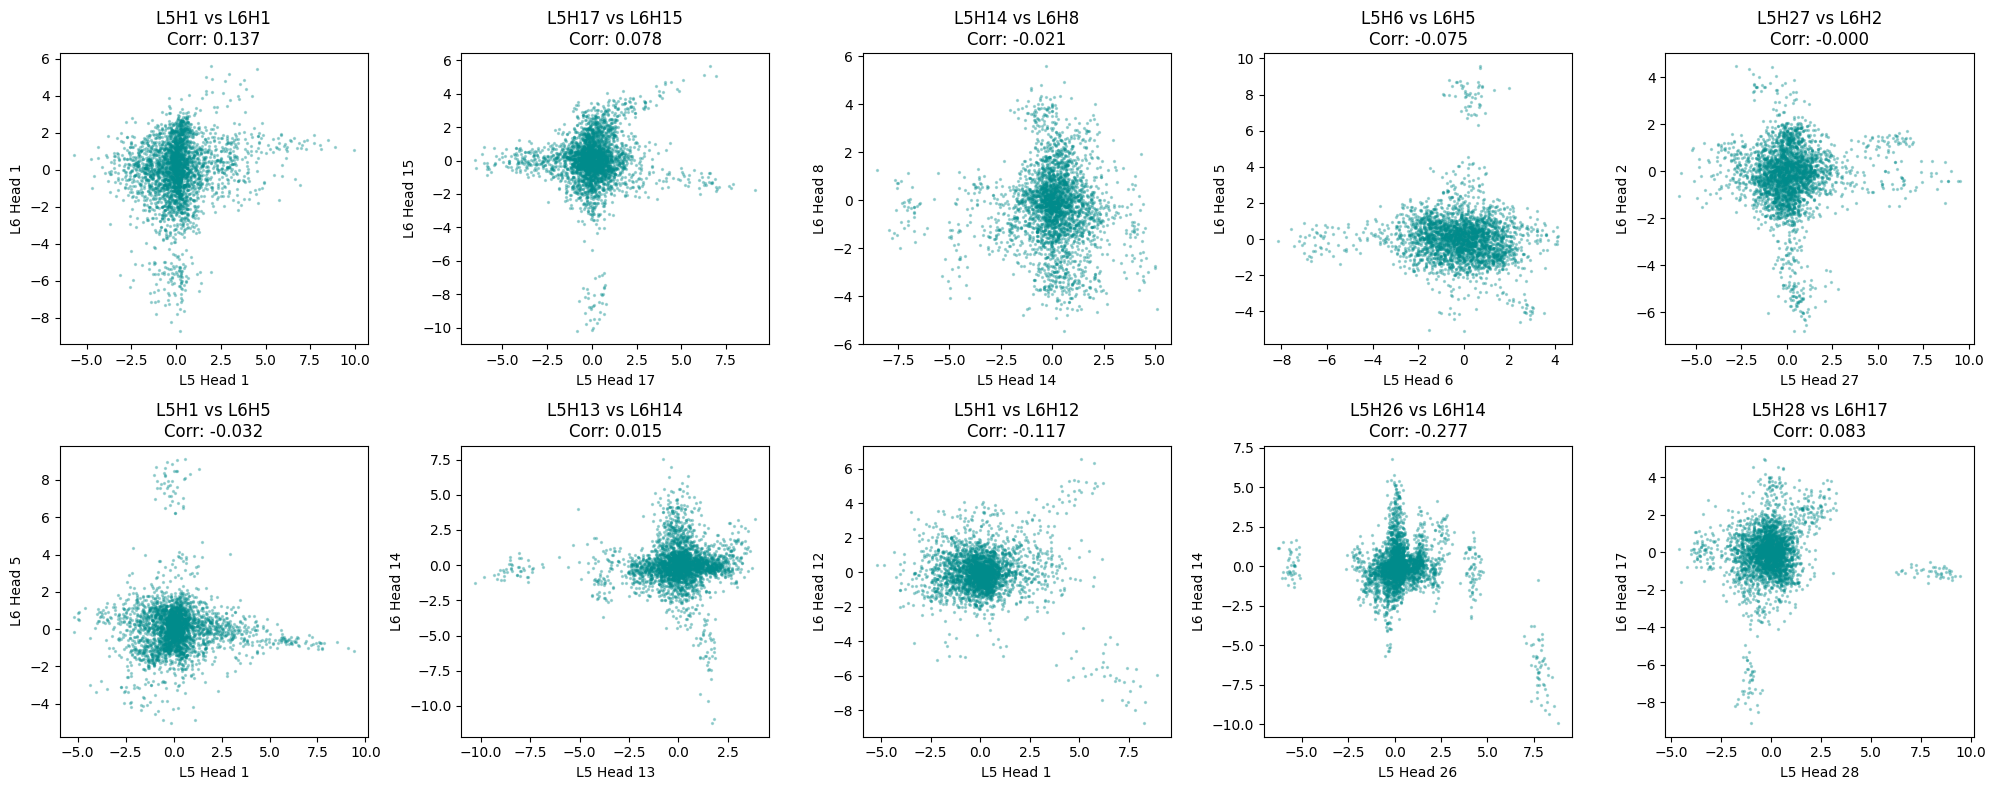

In [ ]:
print("======================================================")
print("EXPERIMENT 1: Layer 5 vs Layer 6 Random Head Correlations")
print("======================================================")

plot_head_correlations(layer_A=5, layer_B=6, num_pairs=10)

EXPERIMENT 2: Consecutive Layer Pairs

Evaluating Consecutive Layers: Layer 5 vs Layer 6


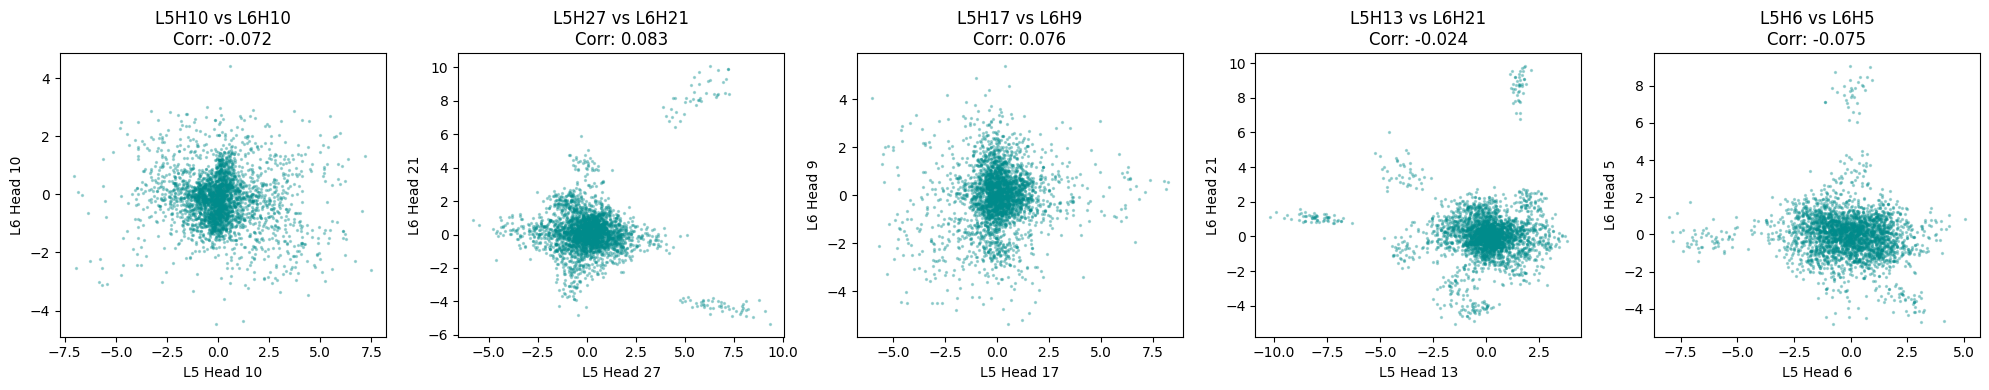


Evaluating Consecutive Layers: Layer 6 vs Layer 7


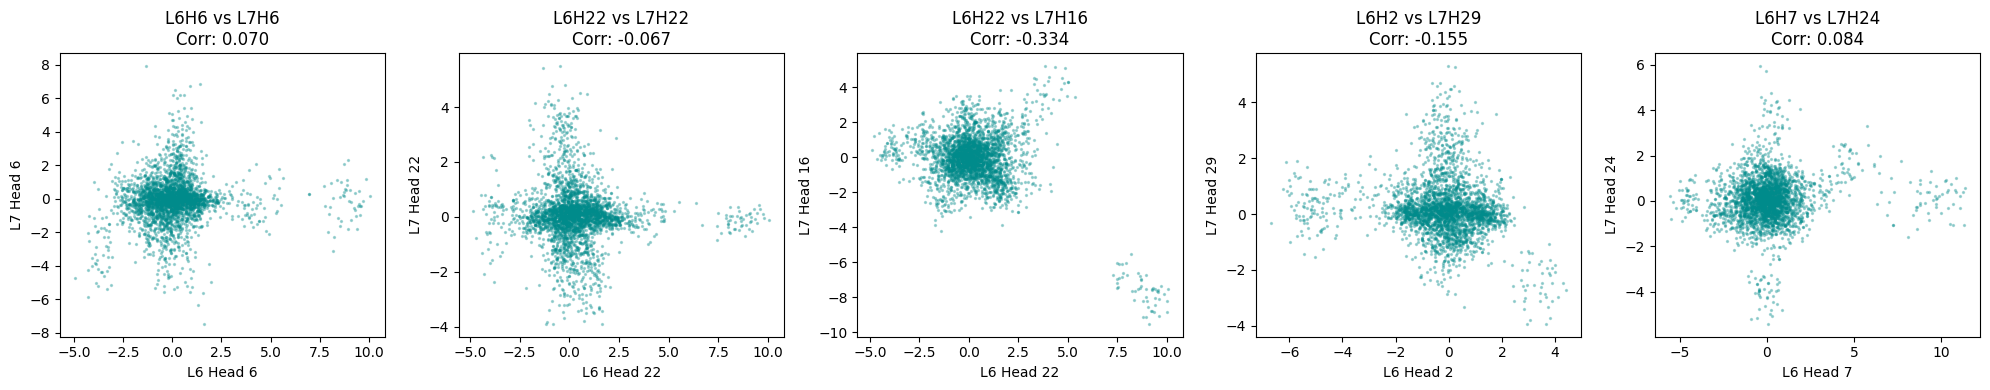


Evaluating Consecutive Layers: Layer 7 vs Layer 8


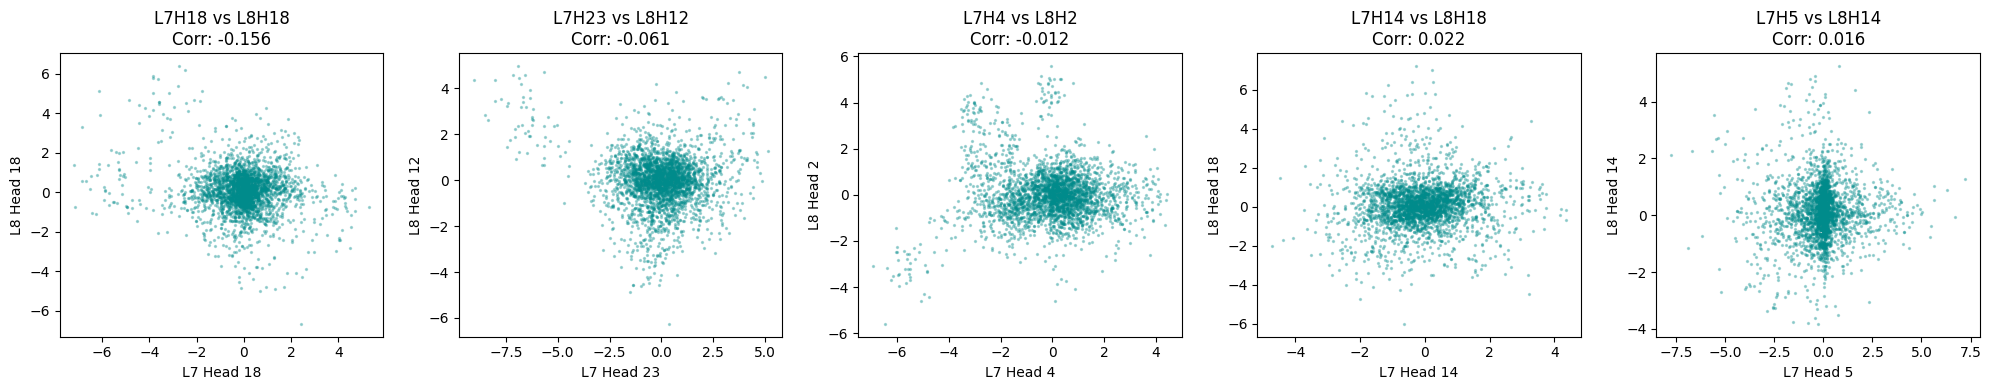

In [ ]:
print("======================================================")
print("EXPERIMENT 2: Consecutive Layer Pairs")
print("======================================================")

# Consecutive pairs from the layers we extracted
consecutive_pairs = [(5, 6), (6, 7), (7, 8)]

for (lA, lB) in consecutive_pairs:
    print(f"\nEvaluating Consecutive Layers: Layer {lA} vs Layer {lB}")
    # We plot fewer pairs per loop (e.g. 5) to keep the charts readable
    plot_head_correlations(layer_A=lA, layer_B=lB, num_pairs=5)

In [ ]:
import torch
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import linregress

# Llama 3.2 1B Config Variables
NUM_Q_HEADS = model.config.num_attention_heads
NUM_KV_HEADS = model.config.num_key_value_heads
HEAD_DIM = model.config.hidden_size // NUM_Q_HEADS

# Dictionary to store per-prompt extracted tensors
# Structure: extracted_states[state_type][layer_idx] = [tensor_p1, tensor_p2, ...]
extracted_states = {
    'q': {l: [] for l in LAYERS_TO_EXTRACT},
    'k': {l: [] for l in LAYERS_TO_EXTRACT},
    'v': {l: [] for l in LAYERS_TO_EXTRACT},
    'attn': {l: [] for l in LAYERS_TO_EXTRACT}
}

def get_hook(state_type, layer_idx):
    def hook(module, input, output):
        # Attention main outputs are often tuples; we just want the tensor
        val = output[0] if isinstance(output, tuple) else output
        # Save per prompt, detach, and move to CPU
        extracted_states[state_type][layer_idx].append(val.detach().cpu())
    return hook

# Register Hooks for Q, K, V, and Attention (o_proj)
hook_handles = []
print("Registering hooks for Q, K, V, and Attention...")
for l_idx in LAYERS_TO_EXTRACT:
    attn_module = model.model.layers[l_idx].self_attn
    hook_handles.append(attn_module.q_proj.register_forward_hook(get_hook('q', l_idx)))
    hook_handles.append(attn_module.k_proj.register_forward_hook(get_hook('k', l_idx)))
    hook_handles.append(attn_module.v_proj.register_forward_hook(get_hook('v', l_idx)))
    hook_handles.append(attn_module.o_proj.register_forward_hook(get_hook('attn', l_idx)))

# Run inference one prompt at a time to perfectly separate prompt distributions
model.eval()
print(f"Running forward passes for {NUM_SAMPLES} prompts...")
with torch.no_grad():
    for i in range(NUM_SAMPLES):
        inputs = tokenizer(prompts[i], return_tensors="pt", truncation=True, max_length=MAX_INPUT_TOKENS).to(DEVICE)
        _ = model(**inputs)

        if (i + 1) % 20 == 0:
            print(f"Processed {i + 1}/{NUM_SAMPLES} prompts...")

# Clean up hooks
for h in hook_handles:
    h.remove()

Registering hooks for Q, K, V, and Attention...
Running forward passes for 100 prompts...
Processed 20/100 prompts...
Processed 40/100 prompts...
Processed 60/100 prompts...
Processed 80/100 prompts...
Processed 100/100 prompts...



--- Plotting Consistency For Layer 5 vs Layer 6 ---


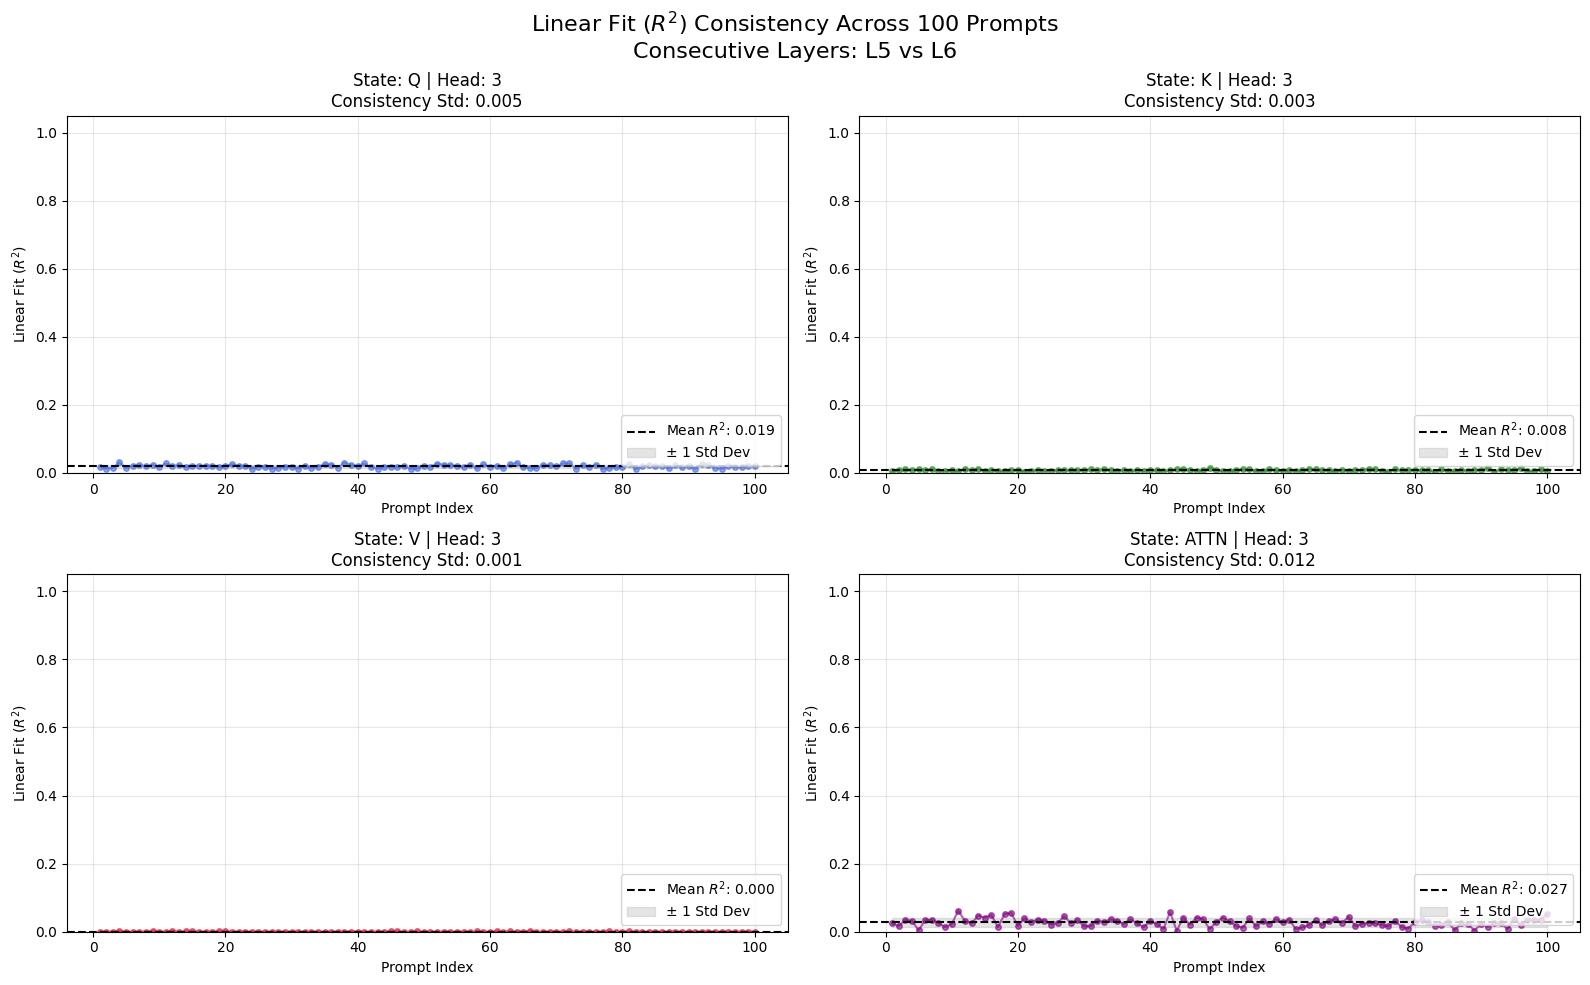

In [ ]:
def analyze_linear_fit_per_prompt(state_type, layer_A, layer_B, head_idx):
    """
    Computes R^2 (Linear fit consistency) for each prompt between layer_A and layer_B
    for the exact same head_idx.
    """
    # Grouped Query Attention handles Q/Attn differently than K/V
    num_heads = NUM_Q_HEADS if state_type in ['q', 'attn'] else NUM_KV_HEADS

    # Ensure the requested head_idx is valid for this state type
    actual_head_idx = head_idx % num_heads

    r2_scores = []

    for prompt_idx in range(NUM_SAMPLES):
        # Shape is [1, seq_len, hidden_size]
        tensor_A = extracted_states[state_type][layer_A][prompt_idx][0]
        tensor_B = extracted_states[state_type][layer_B][prompt_idx][0]

        seq_len = tensor_A.shape[0]

        # Reshape to isolate heads: [seq_len, num_heads, head_dim]
        reshaped_A = tensor_A.view(seq_len, num_heads, HEAD_DIM)
        reshaped_B = tensor_B.view(seq_len, num_heads, HEAD_DIM)

        vec_A = reshaped_A[:, actual_head_idx, :].flatten().numpy().astype(np.float32)
        vec_B = reshaped_B[:, actual_head_idx, :].flatten().numpy().astype(np.float32)

        # Perform Linear Regression to get the fit metric
        slope, intercept, r_value, p_value, std_err = linregress(vec_A, vec_B)

        # R-squared measures how well the linear fit matches the data
        r2_scores.append(r_value ** 2)

    return r2_scores

def plot_consistency(layer_A, layer_B, target_head=3):
    fig, axes = plt.subplots(2, 2, figsize=(16, 10))
    fig.suptitle(f"Linear Fit ($R^2$) Consistency Across {NUM_SAMPLES} Prompts\nConsecutive Layers: L{layer_A} vs L{layer_B}", fontsize=16)

    # Mapping state to a specific subplot and color
    states_config = [
        ('q', target_head, axes[0, 0], 'royalblue'),
        ('k', target_head, axes[0, 1], 'forestgreen'),
        ('v', target_head, axes[1, 0], 'crimson'),
        ('attn', target_head, axes[1, 1], 'purple')
    ]

    for state, head, ax, color in states_config:
        # Calculate per-prompt R^2
        r2_scores = analyze_linear_fit_per_prompt(state, layer_A, layer_B, head)

        mean_r2 = np.mean(r2_scores)
        std_r2 = np.std(r2_scores)

        # Plot the per-prompt line
        ax.plot(range(1, NUM_SAMPLES + 1), r2_scores, marker='o', linestyle='-', color=color, alpha=0.6, markersize=4)

        # Plot mean and standard deviation boundaries
        ax.axhline(mean_r2, color='black', linestyle='--', label=f'Mean $R^2$: {mean_r2:.3f}')
        ax.fill_between(range(1, NUM_SAMPLES + 1), mean_r2 - std_r2, mean_r2 + std_r2, color='gray', alpha=0.2, label='± 1 Std Dev')

        # Using module for head formatting to account for KV having fewer heads
        actual_head = head if state in ['q', 'attn'] else (head % NUM_KV_HEADS)

        ax.set_title(f"State: {state.upper()} | Head: {actual_head}\nConsistency Std: {std_r2:.3f}")
        ax.set_xlabel("Prompt Index")
        ax.set_ylabel("Linear Fit ($R^2$)")
        ax.set_ylim(0, 1.05)
        ax.grid(alpha=0.3)
        ax.legend(loc='lower right')

    plt.tight_layout()
    plt.show()

# Run the plotting experiment on Consecutive Layers L5 and L6, Head 3
print("\n--- Plotting Consistency For Layer 5 vs Layer 6 ---")
plot_consistency(layer_A=5, layer_B=6, target_head=3)